<div style="background:#f7faff;border-left:7px solid #123a9f;padding:18px;border-radius:10px">
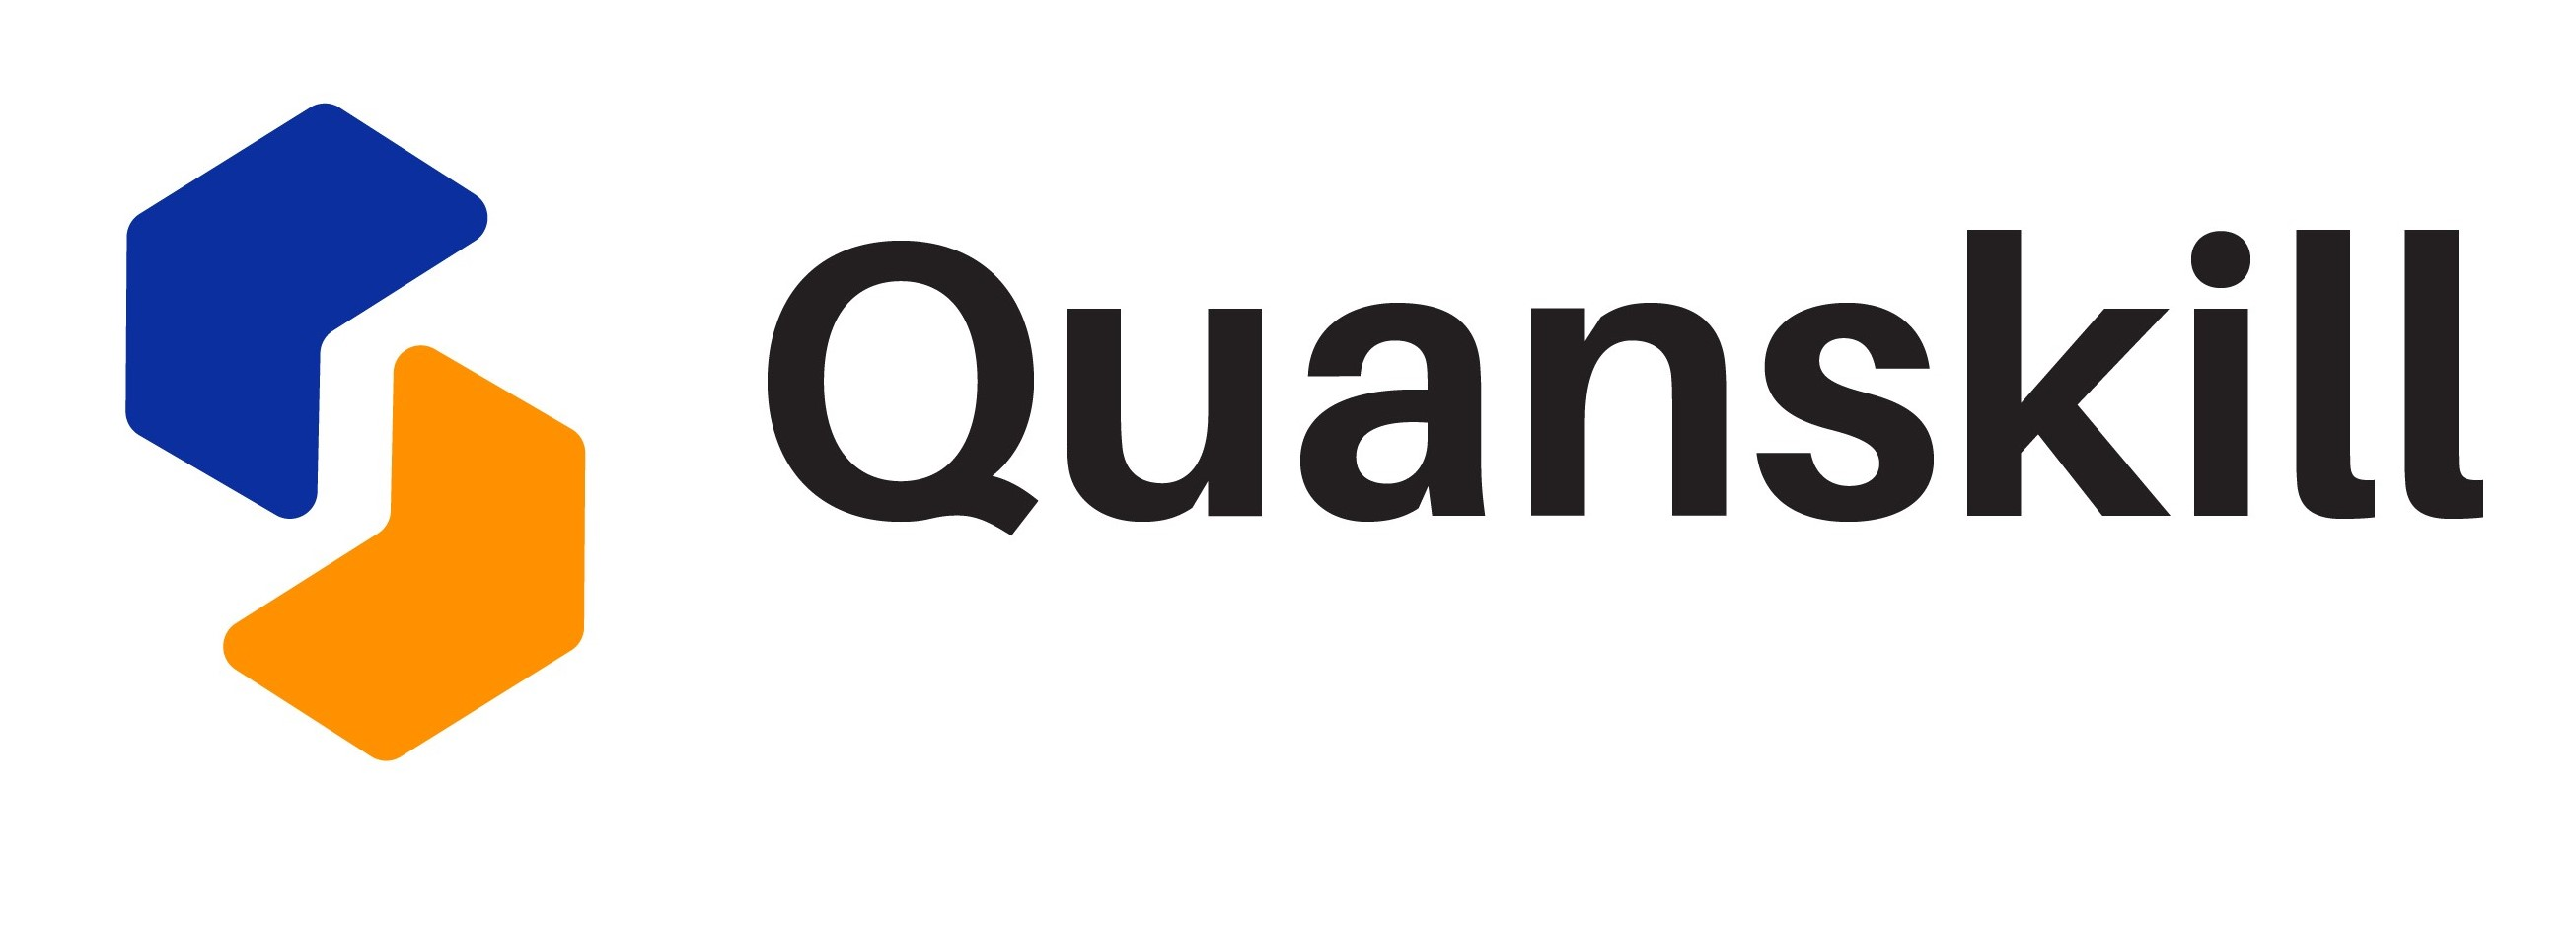
<h1>Chapter 5 · Build the Simplest Baseline First</h1>
<p><b>QuanSkill AI Engineering & Deployment · Week 3 · Fully annotated Colab lab</b></p>
</div>

**Purpose:** Go from a clearly defined question–passage relevance task to no-skill, lexical, and learned classical baselines. Protect evaluation, interpret every metric, inspect mistakes, and save a reusable inference artifact.

**Book navigation:** Chapter 5, printed pp. **403–534** (PDF page = printed page + 26). The practical build is pp. **469–496**. A few compact companion demonstrations cover numeric/categorical features and regression so the broader conceptual sections are teachable too.

**Run:** Runtime → Run all in Google Colab. CPU is sufficient. Default data is a small, deterministic **synthetic teaching dataset**; scores from it are **not research or production claims**. To use your own data, follow the upload cell below with `question_id,question,document_id,page_number,passage,relevant`. No API key, Drive mount, or external dataset download is required.

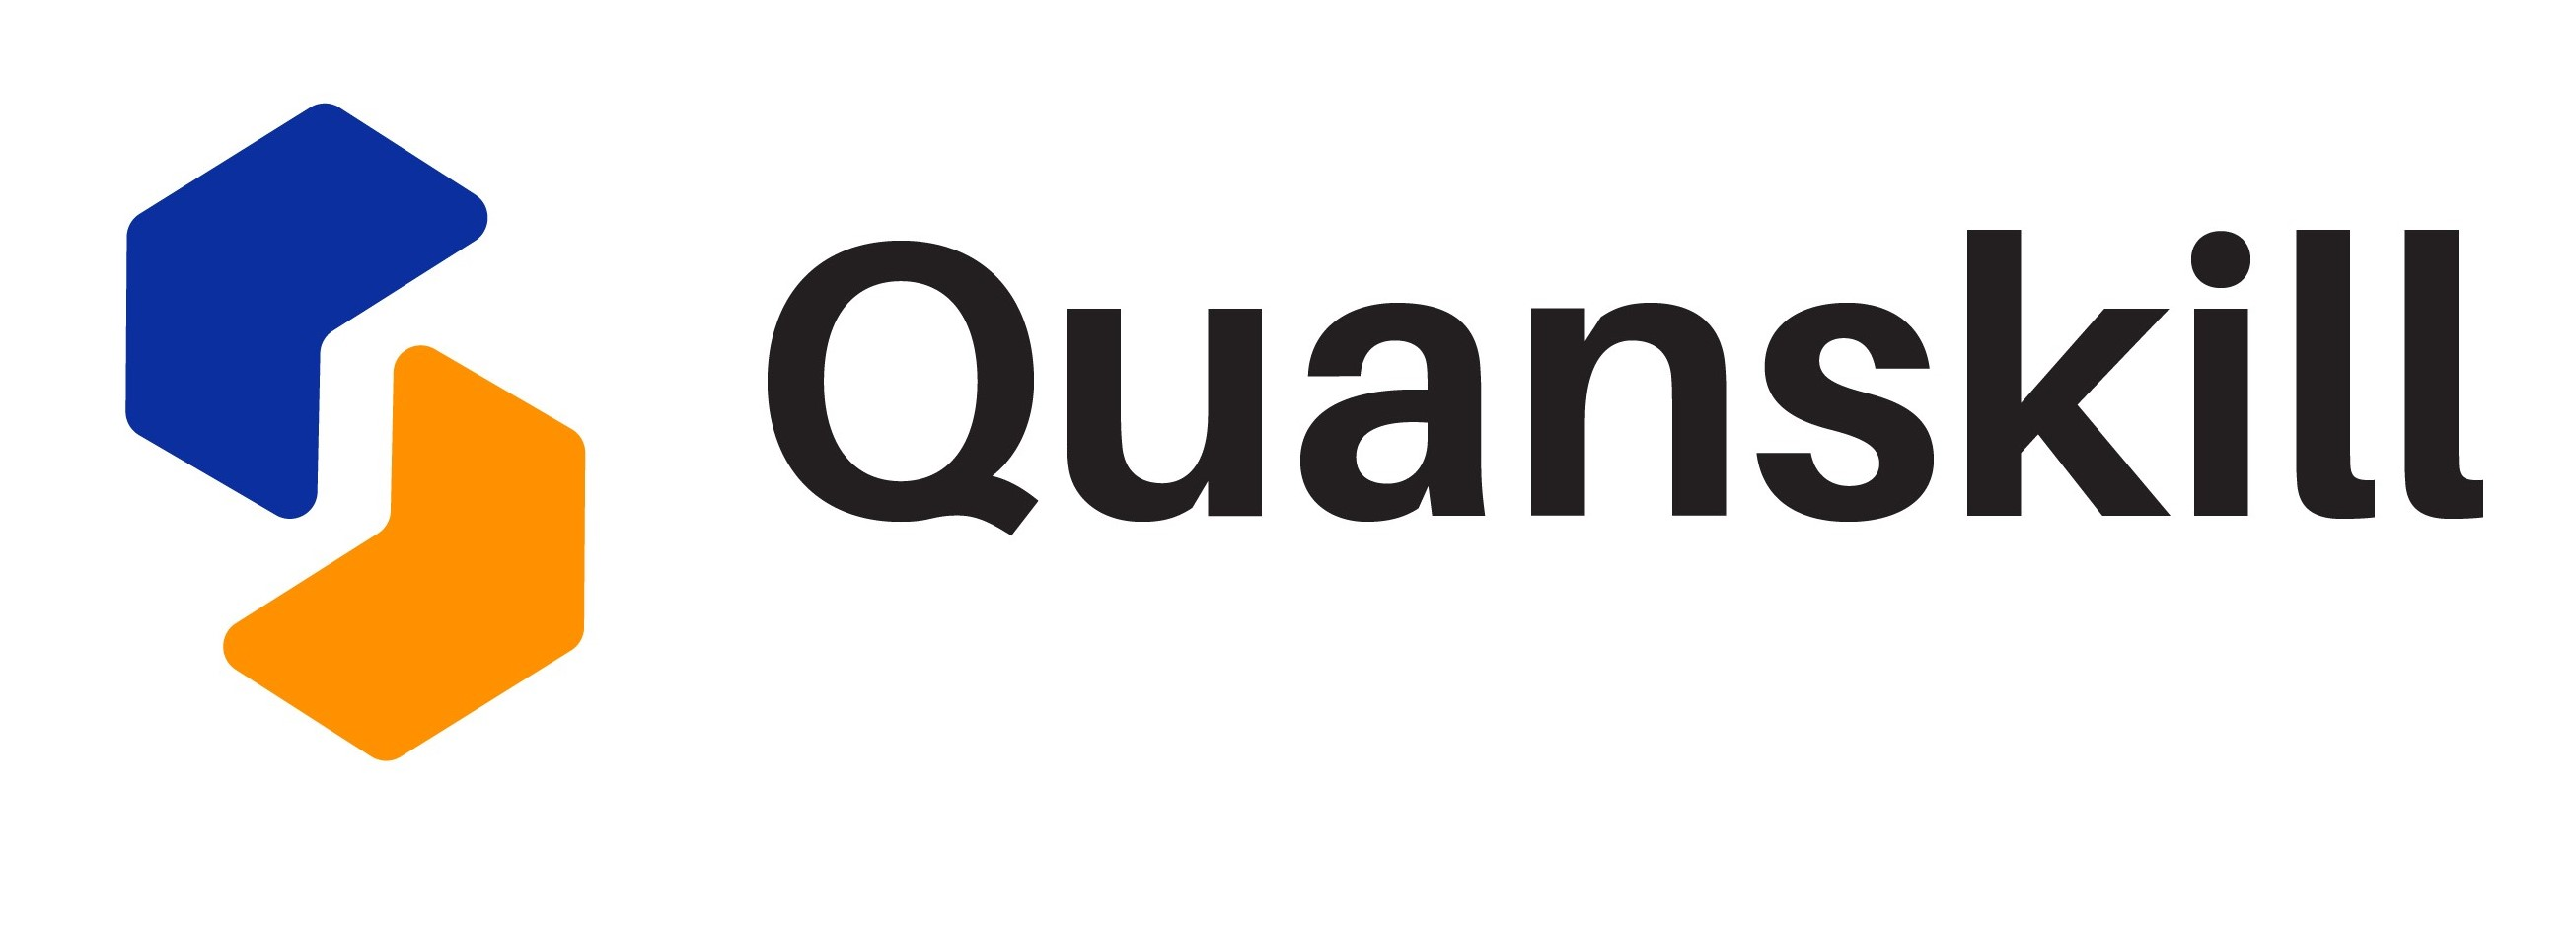

In [1]:
# Portable logo display: the JPEG bytes are embedded inside this notebook.
# This cell also renders it if a notebook viewer sanitizes data-URI images in Markdown.
import base64
from io import BytesIO
from PIL import Image
try:
    from IPython.display import display
except ImportError:  # Standard Python can still execute the notebook's cells.
    def display(obj):
        print(obj)
QUANSKILL_LOGO_B64 = "..."
display(Image.open(BytesIO(base64.b64decode(QUANSKILL_LOGO_B64))))

## Learning map

| Stage | What we will learn | Book pages |
|---|---|---|
| 1 | Task, labels, baseline ladder, new-question split | 403–424 |
| 2 | Features, scaling, categories, Bag of Words, TF–IDF | 425–436 |
| 3 | Logistic regression, tree, forest, regularization, pipeline | 437–454 |
| 4 | Confusion matrix, metrics, thresholds, ROC/PR, calibration | 455–468 |
| 5 | Full experiment and error analysis | 469–504 |
| 6 | Other tracks, acceptance, exercises, business decision | 505–534 |

**Scientific contract:** Split by question, learn preprocessing from training only, select model/threshold on validation, and evaluate the selected procedure on test once. The synthetic demo reuses topic patterns across groups; it estimates performance on its own constructed questions, not new domains or completely unseen source documents.

In [2]:
# Colab normally contains these libraries. The guard avoids unnecessary installs.
import importlib.util, subprocess, sys
requirements = {'numpy':'numpy', 'pandas':'pandas', 'sklearn':'scikit-learn',
                'matplotlib':'matplotlib', 'joblib':'joblib', 'PIL':'Pillow'}
missing = [pip for module,pip in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import re, warnings, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, confusion_matrix, roc_auc_score,
                             average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, mean_absolute_error,
                             mean_squared_error)
print('Environment ready. scikit-learn version:', __import__('sklearn').__version__)

Environment ready. scikit-learn version: 1.9.1


## 1. Define the task and choose data

Our supervised example is **(question, candidate passage) → relevant evidence (1/0)**. A relevant passage contains answer-bearing evidence, not merely topic words. An easy negative is off-topic; a hard negative shares terminology but does not answer the question.

The following short passages were **written for instruction**. Each of 12 topics has four question phrasings; each question gets one positive, one on-topic hard negative, and two unrelated negatives. We deliberately repeat passage templates across questions. This makes the notebook reproducible and useful for testing code, but it is *not an independent research benchmark*.

In [3]:
# Each tuple: four question phrasings, two answer-bearing passages, two hard negatives.
TOPICS = [
 (["Why are scaled attention scores divided by the key dimension root?", "Why scale dot product attention?", "What is the reason for attention scaling?", "How does scaling affect attention training?"],
  ["Large attention dot products can saturate softmax, producing very small gradients; division by the square root of key dimension keeps magnitudes controlled.", "Scaling key query dot products limits the softmax logit magnitude and reduces gradient saturation during optimization."],
  ["Multihead attention runs several attention functions in parallel and concatenates their outputs.", "The attention mechanism forms weights over token positions before aggregating value vectors."]),
 (["Why do recurrent networks struggle with long dependencies?", "What causes vanishing gradients in RNNs?", "How is early sequence information lost?", "Why can recurrent learning forget distant steps?"],
  ["Repeated multiplication by derivatives smaller than one makes influence from early time steps shrink exponentially, causing vanishing gradients.", "Backpropagation through many recurrent steps can attenuate gradients and prevent distant inputs from affecting learned parameters."],
  ["A recurrent model updates a hidden state after reading each token.", "RNNs process sequences with parameters reused at each time step."]),
 (["Why should train and test patients be separated?", "How can patient leakage inflate evaluation?", "Why split medical records by patient ID?", "What does a grouped patient split protect?"],
  ["Visits from the same patient share identity and correlated traits, so placing them in both training and testing overstates performance on new patients.", "Patient grouped evaluation holds every visit from one person in one partition, preventing identity leakage into the held out estimate."],
  ["Hospitals store visit dates and diagnostic codes in electronic records.", "A patient may have multiple visits and many clinical measurements." ]),
 (["What is the purpose of TF IDF in search?", "Why downweight common words in retrieval?", "How does inverse document frequency help?", "Why emphasize rare terms in lexical matching?"],
  ["Inverse document frequency downweights corpus wide common terms and emphasizes words that distinguish fewer documents, improving lexical retrieval signals.", "TF IDF combines term prominence in one passage with inverse frequency across a collection to create weighted text vectors."],
  ["Bag of words counts vocabulary terms in each document without preserving deep meaning.", "A vectorizer tokenizes text and creates a sparse feature matrix." ]),
 (["Why does fitting preprocessing before splitting leak information?", "How does scaling on test data cause leakage?", "Why fit a vectorizer on training only?", "What must the preprocessing boundary protect?"],
  ["Fitting preprocessing on all examples lets validation or test distribution statistics influence the representation used during training, biasing held out evaluation.", "Learn scaler means, category vocabularies and TF IDF document frequencies on training data, then apply the fitted rules unchanged to held out data."],
  ["Standardization subtracts a mean and divides by standard deviation.", "Text preprocessing may include tokenization and lowercasing." ]),
 (["What does precision measure in classification?", "Why can selected passages contain false positives?", "How do we quantify the reliability of positive predictions?", "When the model says relevant how often is it right?"],
  ["Precision divides true positive predictions by all predicted positives, measuring the fraction of selected passages that are actually relevant.", "False positives reduce precision because irrelevant passages are included among the passages the model selects."],
  ["Recall measures the share of actual relevant examples found by a classifier.", "A confusion matrix lists correct and incorrect decisions by true and predicted class." ]),
 (["What does recall measure in evidence retrieval?", "Why are missed relevant passages costly?", "How do false negatives affect recall?", "What fraction of relevant evidence is found?"],
  ["Recall is true positives divided by all actually relevant examples; missed relevant evidence is counted as false negatives.", "A false negative removes a useful passage before downstream answer generation can use its evidence."],
  ["Precision asks what fraction of selected passages are truly relevant.", "Specificity measures how often negatives are correctly rejected." ]),
 (["Why must a threshold be tuned on validation data?", "How does lowering the classification threshold affect recall?", "What happens if test results choose the threshold?", "Why is a default threshold not universally optimal?"],
  ["Choosing a cutoff with validation labels aligns false positives and false negatives to the task; test driven tuning contaminates the final estimate.", "Lowering a score threshold typically selects more cases, increasing recall while often introducing additional false positives."],
  ["A logistic classifier outputs a score after applying the sigmoid function.", "The ROC curve varies the threshold and plots true positive against false positive rate." ]),
 (["Why use group cross validation for research questions?", "How do repeated questions leak across folds?", "Why keep question pairs in one partition?", "What is the unit of generalization in question grouped evaluation?"],
  ["All candidate pairs from one question must stay in the same fold when estimating performance on new questions; row randomization would expose the exact query during training.", "Group aware splitting holds out question identifiers so validation questions have no matching training pairs."],
  ["Cross validation cycles through multiple training and validation folds.", "A research question can be paired with several candidate pages." ]),
 (["How can calibration be checked?", "What does an eighty percent probability mean?", "How does Brier score assess probability quality?", "Why is ranking distinct from calibration?"],
  ["For a calibrated model, about eighty percent of sufficiently many comparable cases scored near zero point eight should be positive.", "Brier score averages squared differences between predicted probabilities and binary outcomes, penalizing overconfident errors."],
  ["ROC AUC measures ranking of positive over negative examples.", "A threshold turns a score into a binary action." ]),
 (["Why can a decision tree overfit?", "How does tree depth affect generalization?", "Why restrict leaf size in a tree?", "What happens when a tree memorizes samples?"],
  ["Deep trees can split until leaves reflect accidental training details; limiting depth and requiring more observations per leaf can improve generalization.", "An unrestricted tree may fit training labels very closely while performing worse on held out question groups."],
  ["A decision tree predicts using a sequence of feature conditions.", "Gini impurity describes how mixed labels are inside a node." ]),
 (["How does a random forest stabilize a decision tree?", "Why train many diversified trees?", "What does a random forest combine?", "How do bootstrap samples help an ensemble?"],
  ["A random forest trains trees on varied bootstrap samples and random feature subsets, then aggregates their votes or probability estimates to reduce instability.", "Combining diversified trees can reduce sensitivity to accidental patterns followed by one decision tree."],
  ["A forest contains several fitted decision trees.", "Feature importance is descriptive and does not establish causality." ]),
]

records = []
for topic_id, (questions, positives, hard_negatives) in enumerate(TOPICS):
    for variant, question in enumerate(questions):
        qid = f'q{topic_id:02d}_{variant}'
        other_a = TOPICS[(topic_id + 3) % len(TOPICS)][1][variant % 2]
        other_b = TOPICS[(topic_id + 7) % len(TOPICS)][1][(variant + 1) % 2]
        examples = [
            (positives[variant % 2], 1, 'positive', topic_id),
            (hard_negatives[(variant + 1) % 2], 0, 'hard_negative', topic_id),
            (other_a, 0, 'easy_negative', (topic_id + 3) % len(TOPICS)),
            (other_b, 0, 'easy_negative', (topic_id + 7) % len(TOPICS)),
        ]
        for j, (passage, label, demo_kind, document_topic) in enumerate(examples):
            records.append(dict(question_id=qid, question=question,
                                document_id=f'demo_doc_{document_topic:02d}_{j}',
                                page_number=1 + j, passage=passage,
                                relevant=label, demo_kind=demo_kind))
demo_df = pd.DataFrame(records)
print(f'{len(demo_df)} pairs / {demo_df.question_id.nunique()} questions / positive prevalence {demo_df.relevant.mean():.1%}')
display(demo_df.head(8))

192 pairs / 48 questions / positive prevalence 25.0%


,question_id,question,document_id,page_number,passage,relevant,demo_kind
0,q00_0,Why are scaled attention scores divided by the...,demo_doc_00_0,1,Large attention dot products can saturate soft...,1,positive
1,q00_0,Why are scaled attention scores divided by the...,demo_doc_00_1,2,The attention mechanism forms weights over tok...,0,hard_negative
2,q00_0,Why are scaled attention scores divided by the...,demo_doc_03_2,3,Inverse document frequency downweights corpus ...,0,easy_negative
3,q00_0,Why are scaled attention scores divided by the...,demo_doc_07_3,4,Lowering a score threshold typically selects m...,0,easy_negative
4,q00_1,Why scale dot product attention?,demo_doc_00_0,1,Scaling key query dot products limits the soft...,1,positive
5,q00_1,Why scale dot product attention?,demo_doc_00_1,2,Multihead attention runs several attention fun...,0,hard_negative
6,q00_1,Why scale dot product attention?,demo_doc_03_2,3,TF IDF combines term prominence in one passage...,0,easy_negative
7,q00_1,Why scale dot product attention?,demo_doc_07_3,4,Choosing a cutoff with validation labels align...,0,easy_negative


### Optional: substitute your real labelled CSV

Set `USE_UPLOAD=True` and rerun this cell and everything below it. In Colab, a file chooser appears. Outside Colab, set `LOCAL_CSV_PATH` to your file. Required columns: `question_id,question,document_id,page_number,passage,relevant` with relevance labels 0/1. **Do not reuse the demo's `demo_kind` as a model feature.** For a serious result, document who labelled pairs, how ambiguous labels were resolved, source permissions, group counts, duplicates, and whether document-level or temporal holdout is needed.

In [4]:
USE_UPLOAD = False
LOCAL_CSV_PATH = ''  # For non-Colab runs, specify a CSV file if USE_UPLOAD=True.
if USE_UPLOAD:
    if LOCAL_CSV_PATH:
        df = pd.read_csv(LOCAL_CSV_PATH)
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise RuntimeError('Provide LOCAL_CSV_PATH when not running in Colab.') from exc
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Upload exactly one CSV file.')
        from io import BytesIO
        df = pd.read_csv(BytesIO(next(iter(uploaded.values()))))
else:
    df = demo_df.copy()

required = {'question_id','question','document_id','page_number','passage','relevant'}
if required - set(df.columns):
    raise ValueError(f'Missing required columns: {sorted(required - set(df.columns))}')
if df[list(required)].isna().any().any():
    raise ValueError('The six required columns cannot have missing values.')
if not set(df.relevant.unique()).issubset({0, 1}) or len(set(df.relevant.unique())) != 2:
    raise ValueError('relevant must contain both binary classes 0 and 1.')
if df.question_id.nunique() < 10:
    raise ValueError('Use at least 10 distinct question IDs for this demonstration.')
if (df.groupby('question_id').question.nunique() > 1).any():
    raise ValueError('One question_id maps to multiple question strings.')
df['relevant'] = df['relevant'].astype(int)
df['question'] = df['question'].astype(str)
df['passage'] = df['passage'].astype(str)
print('Rows:', len(df), 'Questions:', df.question_id.nunique(),
      'Documents:', df.document_id.nunique(), 'Positive prevalence:', round(df.relevant.mean(), 3))
display(df.relevant.value_counts().rename(index={0:'irrelevant',1:'relevant'}))

Rows: 192 Questions: 48 Documents: 48 Positive prevalence: 0.25


relevant
irrelevant    144
relevant       48
Name: count, dtype: int64

## 2. Establish no-skill references and a protected split (pp. 403–424, 469–475)

If 25% of pairs are relevant, predicting 0 always has 75% accuracy and **zero recall**. Accuracy alone cannot establish evidence-finding ability.

**Generalization question:** How well does the method handle a *new question*? `GroupShuffleSplit` keeps all passage pairs for one `question_id` together. It does not guarantee exact row proportions, identical class prevalence, or generalization to unseen source documents.

In [5]:
groups = df['question_id']
first = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
tr_idx, hold_idx = next(first.split(df, y=df['relevant'], groups=groups))
train_df = df.iloc[tr_idx].reset_index(drop=True)
hold_df = df.iloc[hold_idx].reset_index(drop=True)
second = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=43)
va_idx, te_idx = next(second.split(hold_df, y=hold_df.relevant,
                                    groups=hold_df.question_id))
val_df = hold_df.iloc[va_idx].reset_index(drop=True)
test_df = hold_df.iloc[te_idx].reset_index(drop=True)

group_sets = [set(frame.question_id) for frame in (train_df, val_df, test_df)]
assert group_sets[0].isdisjoint(group_sets[1])
assert group_sets[0].isdisjoint(group_sets[2])
assert group_sets[1].isdisjoint(group_sets[2])
for name, frame in [('train',train_df),('validation',val_df),('test',test_df)]:
    print(f'{name:11s} rows={len(frame):3d}, questions={frame.question_id.nunique():2d}, '
          f'positive rate={frame.relevant.mean():.3f}')
    if frame.relevant.nunique() != 2:
        raise ValueError(f'{name} lacks one class. Revise the grouped split or gather more labels.')

# We keep test_df sealed for model selection; do not inspect its outcome again
# until the final test section. The split prevalence check is a design audit.

train       rows=132, questions=33, positive rate=0.250
validation  rows= 28, questions= 7, positive rate=0.250
test        rows= 32, questions= 8, positive rate=0.250


In [6]:
def evaluate_binary(y_true, y_pred, y_score=None, scores_are_probabilities=False):
    """One shared metric contract. Ranking scores need not be calibrated probabilities."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    output = dict(accuracy=accuracy_score(y_true,y_pred),
                  precision=precision_score(y_true,y_pred,zero_division=0),
                  recall=recall_score(y_true,y_pred,zero_division=0),
                  f1=f1_score(y_true,y_pred,zero_division=0),
                  f2=fbeta_score(y_true,y_pred,beta=2,zero_division=0),
                  specificity=tn/(tn+fp) if tn+fp else np.nan,
                  tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp))
    if y_score is not None:
        y_score = np.asarray(y_score)
        output['roc_auc'] = roc_auc_score(y_true,y_score) if len(np.unique(y_true))==2 else np.nan
        output['average_precision'] = average_precision_score(y_true,y_score) if len(np.unique(y_true))==2 else np.nan
        output['brier'] = brier_score_loss(y_true,y_score) if scores_are_probabilities else np.nan
    else:
        output.update(roc_auc=np.nan,average_precision=np.nan,brier=np.nan)
    return output

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(np.zeros((len(train_df),1)), train_df.relevant)
dummy_pred = dummy.predict(np.zeros((len(val_df),1)))
dummy_scores = dummy.predict_proba(np.zeros((len(val_df),1)))[:,list(dummy.classes_).index(1)]
print('Majority validation result:')
display(pd.Series(evaluate_binary(val_df.relevant,dummy_pred,dummy_scores,
                                  scores_are_probabilities=True)).round(3))

Majority validation result:


accuracy              0.75
precision             0.00
recall                0.00
f1                    0.00
f2                    0.00
specificity           1.00
tn                   21.00
fp                    0.00
fn                    7.00
tp                    0.00
roc_auc               0.50
average_precision     0.25
brier                 0.25
dtype: float64

## 3. Feature representations (pp. 425–436)

**Bag of Words:** counts known terms, mostly discarding word order. **Bigrams:** preserve some adjacent word information. **TF–IDF:** combines within-document occurrence with rarity across fitting documents. **Cosine similarity:** compares vector directions. Distinctive terms can be useful without necessarily being semantically meaningful.

For a classic classroom IDF: `log(N / df(term))`. scikit-learn uses configurable smoothing and normalization, so its exact weights need not equal the chalkboard formula.

In [7]:
tiny_texts = ['attention model attention', 'model retrieves document',
              'attention retrieves evidence']
bow = CountVectorizer()
bow_matrix = bow.fit_transform(tiny_texts)
print('Vocabulary:', bow.get_feature_names_out().tolist())
display(pd.DataFrame(bow_matrix.toarray(),columns=bow.get_feature_names_out()))

N = 1000
print('IDF for common term model:', round(np.log(N/800),3))
print('IDF for rarer term recomputation:', round(np.log(N/20),3))
print('Same term frequency 0.1 yields:', round(.1*np.log(N/800),4),
      'versus',round(.1*np.log(N/20),4))

Vocabulary: ['attention', 'document', 'evidence', 'model', 'retrieves']


,attention,document,evidence,model,retrieves
0,2,0,0,1,0
1,0,1,0,1,1
2,1,0,1,0,1


IDF for common term model: 0.223
IDF for rarer term recomputation: 3.912
Same term frequency 0.1 yields: 0.0223 versus 0.3912


In [8]:
# Chapter 5's hand-worked scaling example; learn mean/std on TRAIN only.
train_lengths=np.array([100,120,140,160,180],dtype=float)
scaler_demo=StandardScaler().fit(train_lengths.reshape(-1,1))
print('Train mean:',scaler_demo.mean_[0], 'train population std:',round(scaler_demo.scale_[0],2))
print('Transformed length 180:',round(scaler_demo.transform([[180]])[0,0],2))

# Category IDs for unordered values must not invent numeric order.
cat_demo=pd.DataFrame({'subscription':['Basic','Pro','Basic','Enterprise']})
print('One-hot example:')
display(pd.get_dummies(cat_demo,dtype=int))

Train mean: 140.0 train population std: 28.28
Transformed length 180: 1.41
One-hot example:


,subscription_Basic,subscription_Enterprise,subscription_Pro
0,1,0,0
1,0,0,1
2,1,0,0
3,0,1,0


### Level 1A: token coverage (pp. 407–408, 477–480)

Let `Q` and `P` be lowercase token sets. Coverage = `|Q ∩ P| / |Q|`. This is **not a probability**. We choose its binary cutoff by validation F1. The regex is intentionally simple and English-oriented; examine tokenization for scientific notation or other languages.

In [9]:
TOKEN_PATTERN=re.compile(r'[A-Za-z0-9_]+')
def tokens(text):
    return set(x.lower() for x in TOKEN_PATTERN.findall(str(text)))
def coverage(q,p):
    Q,P=tokens(q),tokens(p)
    return len(Q & P)/len(Q) if Q else 0.0
def jaccard(q,p):
    Q,P=tokens(q),tokens(p)
    return len(Q & P)/len(Q | P) if Q | P else 0.0
def length_ratio(q,p):
    a,b=max(len(tokens(q)),1),max(len(tokens(p)),1)
    return min(a,b)/max(a,b)

assert coverage('attention scale softmax', 'attention softmax gradient score') == 2/3
assert jaccard('attention scale softmax','attention softmax gradient score') == 2/5
print('Coverage example:',round(coverage('attention scale softmax',
                                         'attention softmax gradient score'),3))

def select_threshold(y_true,scores,objective='f1'):
    """Validate on development labels only; ties pick first (lowest) threshold."""
    if objective not in {'f1','f2'}: raise ValueError('Supported: f1 or f2')
    candidates=np.linspace(0,1,101)
    objective_fn=f1_score if objective=='f1' else lambda a,b,zero_division=0: fbeta_score(a,b,beta=2,zero_division=0)
    values=[objective_fn(y_true,np.asarray(scores)>=t,zero_division=0) for t in candidates]
    best=int(np.argmax(values))
    return float(candidates[best]),float(values[best])

val_overlap=np.array([coverage(q,p) for q,p in zip(val_df.question,val_df.passage)])
overlap_threshold, overlap_f1=select_threshold(val_df.relevant,val_overlap)
print('Coverage threshold selected on validation:',overlap_threshold,'F1:',round(overlap_f1,3))

Coverage example: 0.667


Coverage threshold selected on validation: 0.13 F1: 0.667


### Level 1B: TF–IDF cosine similarity (pp. 432–436, 480–481)

Fit vocabulary and document frequencies using **training text only**. The question and passage are transformed separately with the same fitted vectorizer. With L2-normalized rows, their row-wise dot product equals cosine similarity. The threshold is selected on validation.

In [10]:
# min_df=1 makes tiny custom CSVs possible; the original book example uses min_df=2.
# We state the deviation rather than hiding a small-dataset failure.
MIN_DF=2 if len(train_df)>=40 else 1
similarity_vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=MIN_DF,norm='l2')
fit_corpus=pd.concat([train_df.question,train_df.passage],ignore_index=True)
similarity_vectorizer.fit(fit_corpus)

def tfidf_pair_similarity(frame,vectorizer):
    Q=vectorizer.transform(frame.question)
    P=vectorizer.transform(frame.passage)
    return np.asarray(Q.multiply(P).sum(axis=1)).ravel()

val_similarity=tfidf_pair_similarity(val_df,similarity_vectorizer)
similarity_threshold, similarity_f1=select_threshold(val_df.relevant,val_similarity)
print('TF–IDF vocabulary:',len(similarity_vectorizer.vocabulary_),
      'selected validation cutoff:',similarity_threshold,
      'validation F1:',round(similarity_f1,3))

TF–IDF vocabulary: 1053 selected validation cutoff: 0.01 validation F1: 0.588


## 4. Learned model families (pp. 437–445)

**Logistic regression** computes `z = wᵀx + b`, then `σ(z) = 1/(1+exp(-z))`. Its binary cross-entropy penalizes confident mistakes. **Trees** split to reduce impurity (for example Gini `1 - Σ p_class²`). **Random forests** diversify bootstrap-trained trees and aggregate their outputs. **L2** regularization shrinks weights; in scikit-learn a smaller `C` means stronger regularization. Coefficients describe associations in the fitted dataset, not causality.

In [11]:
z=2*.75+1*.40-1
sigmoid=lambda z:1/(1+np.exp(-z))
print('Hand calculation: z=',z,'sigmoid(z)=',round(sigmoid(z),3))
for true_label,pred_prob in [(1,.9),(1,.1),(0,.1),(0,.9)]:
    loss=-(true_label*np.log(pred_prob)+(1-true_label)*np.log(1-pred_prob))
    print(f'y={true_label}, p={pred_prob}: binary cross-entropy={loss:.3f}')
gini_parent=1-(.5**2+.5**2)
gini_right=1-(1/6)**2-(5/6)**2
split_gini=(4/10)*0+(6/10)*gini_right
print('Gini parent:',round(gini_parent,3),'split:',round(split_gini,3),
      'impurity reduction:',round(gini_parent-split_gini,3))

Hand calculation: z= 0.8999999999999999 sigmoid(z)= 0.711
y=1, p=0.9: binary cross-entropy=0.105
y=1, p=0.1: binary cross-entropy=2.303
y=0, p=0.1: binary cross-entropy=0.105
y=0, p=0.9: binary cross-entropy=2.303
Gini parent: 0.5 split: 0.167 impurity reduction: 0.333


### Six hand-engineered pair features + logistic regression (pp. 482–485)

Features: coverage, Jaccard, length ratio, question unique-token length, passage unique-token length, and TF–IDF cosine. `StandardScaler` is **inside** the fitted logistic pipeline. `class_weight='balanced'` is an experimental choice, not a guarantee of improvement.

In [12]:
FEATURE_NAMES=['coverage','jaccard','length_ratio','question_tokens',
               'passage_tokens','tfidf_cosine']
def engineered_features(frame,vectorizer):
    similarities=tfidf_pair_similarity(frame,vectorizer)
    rows=[]
    for i,(q,p) in enumerate(zip(frame.question,frame.passage)):
        rows.append([coverage(q,p),jaccard(q,p),length_ratio(q,p),
                     len(tokens(q)),len(tokens(p)),similarities[i]])
    return np.asarray(rows,dtype=float)

X_train_eng=engineered_features(train_df,similarity_vectorizer)
X_val_eng=engineered_features(val_df,similarity_vectorizer)
feature_lr=Pipeline([('scale',StandardScaler()),
                     ('model',LogisticRegression(max_iter=2000,
                      class_weight='balanced',random_state=42))])
feature_lr.fit(X_train_eng,train_df.relevant)
feature_val_scores=feature_lr.predict_proba(X_val_eng)[:,1]
feature_threshold, feature_f1=select_threshold(val_df.relevant,feature_val_scores)
display(pd.DataFrame(X_train_eng[:5],columns=FEATURE_NAMES).round(3))
print('Feature LR validation F1:',round(feature_f1,3))
display(pd.Series(feature_lr.named_steps['model'].coef_[0],index=FEATURE_NAMES,
                  name='scaled-feature coefficient').sort_values(ascending=False))

,coverage,jaccard,length_ratio,question_tokens,passage_tokens,tfidf_cosine
0,0.545,0.222,0.500,11.0,22.0,0.197
1,0.182,0.095,0.917,11.0,12.0,0.034
2,0.000,0.000,0.579,11.0,19.0,0.000
3,0.000,0.000,0.688,11.0,16.0,0.000
4,0.200,0.050,0.312,5.0,16.0,0.043


Feature LR validation F1: 0.667


coverage           1.459327
tfidf_cosine       0.609385
question_tokens    0.581413
jaccard            0.104647
passage_tokens    -0.014211
length_ratio      -1.274641
Name: scaled-feature coefficient, dtype: float64

### Sparse pair text + TF–IDF logistic regression (pp. 485–487)

The question and passage are joined with explicit markers. The pipeline learns TF–IDF and logistic regression **together inside training**. `sublinear_tf=True` dampens repeated-token counts. This is a baseline representation; concatenation does not guarantee semantic understanding of the relationship.

**HOMEWORK 2D — controlled experiment (run 2).** Exactly one development choice changed: the sparse TF–IDF
logistic regression uses `C=10.0` instead of the default `C=1.0` (weaker L2 regularization). Same data, same seeds (42/43),
same split, same everything else. **Hypothesis:** if the sparse model's near-chance validation AP (0.246 in run 1) were caused
by over-regularization of 1,118 sparse features on 132 training rows, C=10 would raise its validation AP and F1. If the cause is the
representation (concatenated pair text encodes topic words, not whether the passage answers the question), AP stays near prevalence (0.25).
The test result printed further below is **exploratory**; the formal test result is run 1's.

In [13]:
def combine_pair_text(frame):
    return 'QUESTION: '+frame.question.astype(str)+'\nPASSAGE: '+frame.passage.astype(str)

text_lr=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=MIN_DF,
                                         max_df=.98,sublinear_tf=True)),
                  ('model',LogisticRegression(max_iter=2000,C=10.0,  # HOMEWORK 2D: only change (default C=1.0)
                                             class_weight='balanced',random_state=42))])
text_lr.fit(combine_pair_text(train_df),train_df.relevant)
text_val_scores=text_lr.predict_proba(combine_pair_text(val_df))[:,1]
text_threshold,text_f1=select_threshold(val_df.relevant,text_val_scores)
print('Sparse text LR vocabulary:',len(text_lr.named_steps['tfidf'].vocabulary_),
      'validation F1:',round(text_f1,3),'threshold:',text_threshold)

Sparse text LR vocabulary: 1118 validation F1: 0.5 threshold: 0.23


### Optional model-shape comparison: tree and forest (pp. 440–444, 487–488)

A shallow tree exposes rules and a forest tests nonlinear interactions among six engineered features. The tree and forest are built on the same training feature matrix. They are comparisons, not assumed winners.

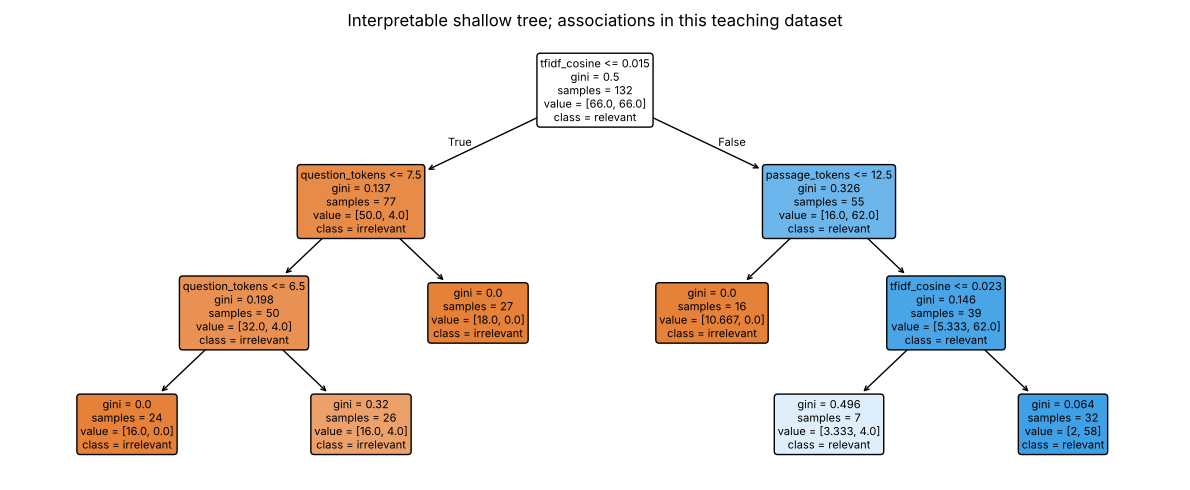

In [14]:
tree=DecisionTreeClassifier(max_depth=3,min_samples_leaf=3,
                            class_weight='balanced',random_state=42)
forest=RandomForestClassifier(n_estimators=120,max_depth=6,min_samples_leaf=3,
                              class_weight='balanced',random_state=42,n_jobs=-1)
tree.fit(X_train_eng,train_df.relevant)
forest.fit(X_train_eng,train_df.relevant)
tree_val_scores=tree.predict_proba(X_val_eng)[:,1]
forest_val_scores=forest.predict_proba(X_val_eng)[:,1]
tree_threshold,_=select_threshold(val_df.relevant,tree_val_scores)
forest_threshold,_=select_threshold(val_df.relevant,forest_val_scores)
fig,ax=plt.subplots(figsize=(12,5))
plot_tree(tree,feature_names=FEATURE_NAMES,class_names=['irrelevant','relevant'],
          filled=True,rounded=True,fontsize=8,ax=ax)
plt.title('Interpretable shallow tree; associations in this teaching dataset')
plt.tight_layout();plt.show()

### Grouped cross-validation: leakage has two boundaries (pp. 445–454)

The pipeline refits its TF–IDF and classifier inside each training fold. `GroupKFold` ensures that an entire research question stays in one fold. Using only a pipeline with random row folds still leaks question wording; using only group folds with TF–IDF fitted globally still leaks held-out vocabulary.

In [15]:
# Development/training data only. Test examples do not take part in model selection.
group_cv=GroupKFold(n_splits=3)
fold_results=[]
for fold,(idx_train,idx_hold) in enumerate(group_cv.split(train_df,
                 y=train_df.relevant,groups=train_df.question_id),start=1):
    inner_train=train_df.iloc[idx_train]
    inner_hold=train_df.iloc[idx_hold]
    local_model=clone(text_lr).fit(combine_pair_text(inner_train),inner_train.relevant)
    scores=local_model.predict_proba(combine_pair_text(inner_hold))[:,1]
    preds=(scores>=.5).astype(int)  # fixed threshold for a clean CV demonstration
    fold_results.append({'fold':fold,'questions':inner_hold.question_id.nunique(),
                         'f1_at_0.5':f1_score(inner_hold.relevant,preds,zero_division=0),
                         'average_precision':average_precision_score(inner_hold.relevant,scores)})
display(pd.DataFrame(fold_results).round(3))
print('For a final model policy, choose threshold on validation; no test involvement.')

,fold,questions,f1_at_0.5,average_precision
0,1,11,0.55,0.396
1,2,11,0.40,0.377
2,3,11,0.37,0.264


For a final model policy, choose threshold on validation; no test involvement.


## 5. Compare on validation; freeze a decision (pp. 455–491)

Every model uses the *same validation questions and metric function*. The majority predictor supplies the no-skill reference. Numeric lexical scores are suitable for ranking comparisons, but the Brier score is intentionally left undefined for those scores because they were not probability estimators. `predict_proba` outputs from classifiers are used for an **exploratory** Brier score; calibration is not guaranteed.

In [16]:
candidates={
    'majority':(dummy_scores,float(0.5),True),
    'token_coverage':(val_overlap,overlap_threshold,False),
    'tfidf_similarity':(val_similarity,similarity_threshold,False),
    'engineered_logistic':(feature_val_scores,feature_threshold,True),
    'sparse_tfidf_logistic':(text_val_scores,text_threshold,True),
    'shallow_tree':(tree_val_scores,tree_threshold,True),
    'random_forest':(forest_val_scores,forest_threshold,True),
}
validation_results={}
for name,(scores,tau,is_prob) in candidates.items():
    predictions=dummy_pred if name=='majority' else (scores>=tau).astype(int)
    validation_results[name]=evaluate_binary(val_df.relevant,predictions,scores,
                                              scores_are_probabilities=is_prob)
validation_table=pd.DataFrame(validation_results).T.sort_values('f1',ascending=False)
display(validation_table.round(3))

,accuracy,precision,recall,f1,f2,specificity,tn,fp,fn,tp,roc_auc,average_precision,brier
random_forest,0.893,0.833,0.714,0.769,0.735,0.952,20.0,1.0,2.0,5.0,0.752,0.766,0.112
shallow_tree,0.857,0.714,0.714,0.714,0.714,0.905,19.0,2.0,2.0,5.0,0.782,0.554,0.150
token_coverage,0.821,0.625,0.714,0.667,0.694,0.857,18.0,3.0,2.0,5.0,0.772,0.589,NaN
engineered_logistic,0.821,0.625,0.714,0.667,0.694,0.857,18.0,3.0,2.0,5.0,0.850,0.679,0.127
tfidf_similarity,0.750,0.500,0.714,0.588,0.658,0.762,16.0,5.0,2.0,5.0,0.707,0.390,NaN
sparse_tfidf_logistic,0.500,0.333,1.000,0.500,0.714,0.333,7.0,14.0,0.0,7.0,0.510,0.260,0.273
majority,0.750,0.000,0.000,0.000,0.000,1.000,21.0,0.0,7.0,0.0,0.500,0.250,0.250


**Selection policy for this teaching lab:** Choose the highest validation F1; if tied, select the simpler method from the written baseline ladder. Inspect recall, precision, AP, and individual errors before accepting that policy in an application. Validation-tuned threshold and validation comparison share the same small holdout; its best F1 is optimistic. The **one-time test** estimates the chosen policy's behavior on held-out question groups.

To experiment with a custom policy, set `FINAL_MODEL_NAME` manually from the table **before running the test cell**.

In [17]:
# Models with a deployable scoring function and fixed selection threshold.
model_ladder=['majority','token_coverage','tfidf_similarity',
              'engineered_logistic','sparse_tfidf_logistic','shallow_tree','random_forest']
ranked=sorted(model_ladder,key=lambda n:(-validation_results[n]['f1'],model_ladder.index(n)))
FINAL_MODEL_NAME=ranked[0]
thresholds={name:details[1] for name,details in candidates.items()}
FINAL_THRESHOLD=thresholds[FINAL_MODEL_NAME]
print('FROZEN before final test:',FINAL_MODEL_NAME,
      'threshold=',FINAL_THRESHOLD,
      'validation F1=',round(validation_results[FINAL_MODEL_NAME]['f1'],3))
print('This is a teaching-data choice, not evidence of real-world superiority.')

FROZEN before final test: random_forest threshold= 0.56 validation F1= 0.769
This is a teaching-data choice, not evidence of real-world superiority.


### Metric hand calculation (pp. 455–462)

Using the book's fixed example `TP=18, FP=12, TN=63, FN=7`, manually derive accuracy `81%`, precision `60%`, recall `72%`, F1 `36/55 ≈ 65.5%`, specificity `84%`. One number does not explain every kind of mistake.

In [18]:
tp,fp,tn,fn=18,12,63,7
p=tp/(tp+fp);r=tp/(tp+fn)
worked={'accuracy':(tp+tn)/(tp+fp+tn+fn),'precision':p,'recall':r,
        'f1':2*p*r/(p+r),'specificity':tn/(tn+fp),
        'f2':5*p*r/(4*p+r)}
display(pd.Series(worked,name='Book worked example').round(3))
assert abs(worked['f1']-36/55)<1e-12

accuracy       0.810
precision      0.600
recall         0.720
f1             0.655
specificity    0.840
f2             0.692
Name: Book worked example, dtype: float64

### Threshold policy, ranking, and calibration (pp. 463–468)

Changing the cutoff changes false positives and false negatives without retraining. `ROC-AUC` asks how often a positive outranks a negative; `Average Precision` summarizes precision along a ranked list. A `0.8` model output is **calibrated** only if many comparable cases near `0.8` are positive about 80% of the time. Calibration needs sufficient representative data; the synthetic dataset cannot establish it.

In [19]:
# Fully worked eight-item example from the teaching script.
toy_scores=np.array([.95,.82,.74,.62,.55,.48,.30,.10])
toy_y=np.array([1,0,1,0,1,0,0,0])
for tau in [.90,.70,.50]:
    m=evaluate_binary(toy_y,(toy_scores>=tau).astype(int),toy_scores,
                      scores_are_probabilities=True)
    print('threshold',tau,'TP FP FN TN:',m['tp'],m['fp'],m['fn'],m['tn'],
          'precision',round(m['precision'],3),'recall',round(m['recall'],3))
print('Toy ROC-AUC:',roc_auc_score(toy_y,toy_scores),
      'Toy Average Precision:',round(average_precision_score(toy_y,toy_scores),3))
print('Brier contributions for a positive with score .9 vs .2:',(.9-1)**2,(.2-1)**2)

threshold 0.9 TP FP FN TN: 1 0 2 5 precision 1.0 recall 0.333
threshold 0.7 TP FP FN TN: 2 1 1 4 precision 0.667 recall 0.667
threshold 0.5 TP FP FN TN: 3 2 0 3 precision 0.6 recall 1.0
Toy ROC-AUC: 0.8 Toy Average Precision: 0.756
Brier contributions for a positive with score .9 vs .2: 0.009999999999999995 0.6400000000000001


## 6. Final held-out test, once (pp. 491–496)

The following cell evaluates the **already selected** procedure. Do not use its result to switch models or tune a threshold while still calling it an independent final test. Our target is unseen question IDs in this teaching dataset; repeated source patterns and generated phrasing limit any broader claim.

In [20]:
def score_pairs(frame,model_name):
    if model_name=='majority':
        return dummy.predict_proba(np.zeros((len(frame),1)))[:,list(dummy.classes_).index(1)]
    if model_name=='token_coverage':
        return np.array([coverage(q,p) for q,p in zip(frame.question,frame.passage)])
    if model_name=='tfidf_similarity':
        return tfidf_pair_similarity(frame,similarity_vectorizer)
    if model_name=='engineered_logistic':
        return feature_lr.predict_proba(engineered_features(frame,similarity_vectorizer))[:,1]
    if model_name=='sparse_tfidf_logistic':
        return text_lr.predict_proba(combine_pair_text(frame))[:,1]
    if model_name=='shallow_tree':
        return tree.predict_proba(engineered_features(frame,similarity_vectorizer))[:,1]
    if model_name=='random_forest':
        return forest.predict_proba(engineered_features(frame,similarity_vectorizer))[:,1]
    raise KeyError(model_name)

test_scores=score_pairs(test_df,FINAL_MODEL_NAME)
test_predictions=(test_scores>=FINAL_THRESHOLD).astype(int)
if FINAL_MODEL_NAME=='majority':
    test_predictions=dummy.predict(np.zeros((len(test_df),1)))
probability_model=FINAL_MODEL_NAME in {'majority','engineered_logistic',
                       'sparse_tfidf_logistic','shallow_tree','random_forest'}
test_metrics=evaluate_binary(test_df.relevant,test_predictions,test_scores,
                             scores_are_probabilities=probability_model)
print('FINAL TEST on held-out questions. Model:',FINAL_MODEL_NAME,'Threshold:',FINAL_THRESHOLD)
display(pd.Series(test_metrics).round(3))
display(pd.DataFrame(confusion_matrix(test_df.relevant,test_predictions,labels=[0,1]),
                     index=['Actual irrelevant','Actual relevant'],
                     columns=['Predicted irrelevant','Predicted relevant']))

FINAL TEST on held-out questions. Model: random_forest Threshold: 0.56


accuracy              0.875
precision             1.000
recall                0.500
f1                    0.667
f2                    0.556
specificity           1.000
tn                   24.000
fp                    0.000
fn                    4.000
tp                    4.000
roc_auc               0.857
average_precision     0.804
brier                 0.103
dtype: float64

,Predicted irrelevant,Predicted relevant
Actual irrelevant,24,0
Actual relevant,4,4


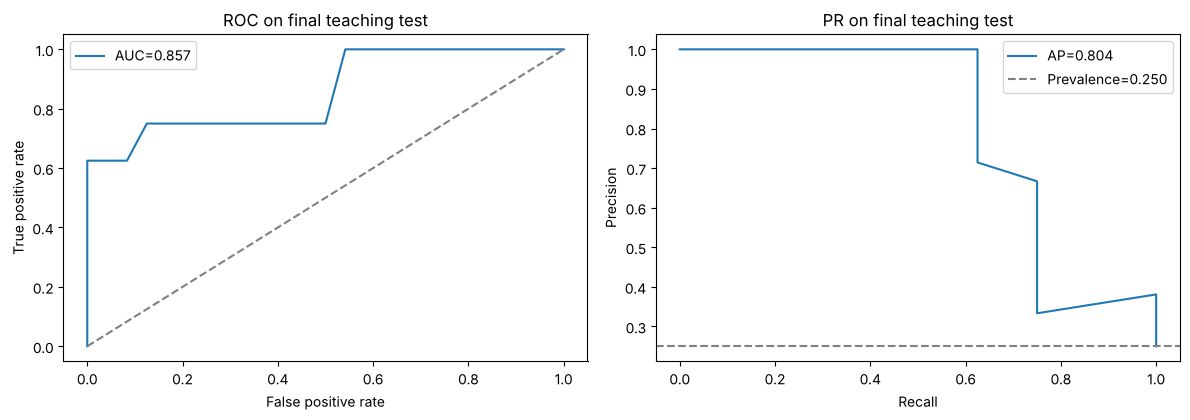

In [21]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,4.3))
fpr,tpr,_=roc_curve(test_df.relevant,test_scores)
ax1.plot(fpr,tpr,label=f"AUC={test_metrics['roc_auc']:.3f}")
ax1.plot([0,1],[0,1],'--',color='gray');ax1.set(xlabel='False positive rate',
    ylabel='True positive rate',title='ROC on final teaching test');ax1.legend()
pr,rec,_=precision_recall_curve(test_df.relevant,test_scores)
ax2.plot(rec,pr,label=f"AP={test_metrics['average_precision']:.3f}")
ax2.axhline(test_df.relevant.mean(),ls='--',color='gray',
            label=f'Prevalence={test_df.relevant.mean():.3f}')
ax2.set(xlabel='Recall',ylabel='Precision',title='PR on final teaching test');ax2.legend()
plt.tight_layout();plt.show()

## 7. Error analysis by passage *and* question (pp. 497–504)

Read the source page for confident false positives and false negatives. Sort cases into: on-topic but not answer-bearing, lexical paraphrase, extraction/chunk damage, disputed label, or threshold-only error. A more powerful model is justified only when the failure pattern and evaluation support that next experiment.

Pairwise recall can mask unanswered questions. Question hit rate = fraction of held-out questions with **at least one** true positive, among questions with at least one labelled relevant candidate.

In [22]:
review=test_df.copy()
review['score']=test_scores;review['prediction']=test_predictions
fp_df=review[(review.relevant==0)&(review.prediction==1)].sort_values('score',ascending=False)
fn_df=review[(review.relevant==1)&(review.prediction==0)].sort_values('score')
print('Highest-scoring false positives:')
display(fp_df[['question_id','question','document_id','page_number','passage','score']].head(5))
print('Lowest-scoring false negatives:')
display(fn_df[['question_id','question','document_id','page_number','passage','score']].head(5))

review['found_positive']=((review.relevant==1)&(review.prediction==1)).astype(int)
by_question=review.groupby('question_id',as_index=False).agg(
    positives=('relevant','sum'),found=('found_positive','sum'))
eligible=by_question[by_question.positives>0].copy()
eligible['recall']=eligible.found/eligible.positives
eligible['hit']=(eligible.found>0).astype(int)
print('Pair recall:',round(test_metrics['recall'],3),
      'Question hit rate:',round(eligible.hit.mean(),3))
display(eligible.head(12))

Highest-scoring false positives:


,question_id,question,document_id,page_number,passage,score


Lowest-scoring false negatives:


,question_id,question,document_id,page_number,passage,score
8,q06_1,Why are missed relevant passages costly?,demo_doc_06_0,1,A false negative removes a useful passage befo...,0.089364
24,q09_3,Why is ranking distinct from calibration?,demo_doc_09_0,1,Brier score averages squared differences betwe...,0.089364
20,q09_1,What does an eighty percent probability mean?,demo_doc_09_0,1,Brier score averages squared differences betwe...,0.304391
0,q01_2,How is early sequence information lost?,demo_doc_01_0,1,Repeated multiplication by derivatives smaller...,0.406913


Pair recall: 0.5 Question hit rate: 0.5


,question_id,positives,found,recall,hit
0,q01_2,1,0,0.0,0
1,q06_0,1,1,1.0,1
2,q06_1,1,0,0.0,0
3,q06_2,1,1,1.0,1
4,q06_3,1,1,1.0,1
5,q09_1,1,0,0.0,0
6,q09_3,1,0,0.0,0
7,q10_3,1,1,1.0,1


### Manual audit worksheet

| Question ID | Error type | Score | Source page checked? | Likely cause | Next experiment |
|---|---|---:|---|---|---|
| ... | FP: topic, no answer | ... | ... | lexical match | hard negatives / better representation |
| ... | FN: paraphrase | ... | ... | semantic mismatch | embeddings comparison |
| ... | FN: extraction | ... | ... | missing text | repair Week 2 pipeline |

**Do not assign these example categories automatically from the model score.** Read the passages and record actual counts in a real error taxonomy. A near-threshold miss may respond to a different cutoff; a relevant passage buried at a very low score suggests a deeper ranking problem.

## 8. Save and reload the complete inference path (pp. 495–496)

Save the fitted transformation(s), estimator, chosen threshold, split unit, and feature version together. This Colab runtime writes under `/content` in Colab or the current workspace elsewhere. **Only load `.joblib` artifacts you created or trust**; loading untrusted pickles can execute code.

In [23]:
OUTPUT_DIR=Path('/content/quanskill_ch5' if Path('/content').exists() else 'quanskill_ch5_output')
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
artifact={'model_name':FINAL_MODEL_NAME,'threshold':float(FINAL_THRESHOLD),
          'split_unit':'question_id','features_version':'chapter5_v1',
          'class_labels':{0:'irrelevant',1:'relevant'},
          'scoring_objects':{'dummy':dummy,'similarity_vectorizer':similarity_vectorizer,
              'feature_lr':feature_lr,'text_lr':text_lr,'tree':tree,'forest':forest}}
artifact_path=OUTPUT_DIR/'week03_relevance_baseline.joblib'
joblib.dump(artifact,artifact_path)
reloaded=joblib.load(artifact_path) # Only our own file.

def predict_relevance(question,passage,stored):
    row=pd.DataFrame({'question':[question],'passage':[passage]})
    name=stored['model_name'];obj=stored['scoring_objects']
    if name=='majority': score=float(obj['dummy'].predict_proba(np.zeros((1,1)))[:,list(obj['dummy'].classes_).index(1)][0])
    elif name=='token_coverage': score=coverage(question,passage)
    elif name=='tfidf_similarity': score=float(tfidf_pair_similarity(row,obj['similarity_vectorizer'])[0])
    elif name=='engineered_logistic': score=float(obj['feature_lr'].predict_proba(engineered_features(row,obj['similarity_vectorizer']))[0,1])
    elif name=='sparse_tfidf_logistic': score=float(obj['text_lr'].predict_proba(combine_pair_text(row))[0,1])
    elif name=='shallow_tree': score=float(obj['tree'].predict_proba(engineered_features(row,obj['similarity_vectorizer']))[0,1])
    elif name=='random_forest': score=float(obj['forest'].predict_proba(engineered_features(row,obj['similarity_vectorizer']))[0,1])
    else: raise ValueError('Unknown saved model')
    return {'model':name,'score':round(score,4),
            'predicted_relevant':int(score>=stored['threshold']),
            'threshold':stored['threshold'],
            'score_is_probability_estimate':name in {'majority','engineered_logistic',
                              'sparse_tfidf_logistic','shallow_tree','random_forest'}}

example_question='Why are attention scores scaled?'
example_passage='Scaling reduces very large dot products before softmax, preventing tiny gradients.'
display(predict_relevance(example_question,example_passage,reloaded))
print('Saved:',artifact_path)

{'model': 'random_forest',
 'score': 0.0392,
 'predicted_relevant': 0,
 'threshold': 0.56,
 'score_is_probability_estimate': True}

Saved: quanskill_ch5_output/week03_relevance_baseline.joblib


## 9. Other Chapter 5 task types: regression and mixed tabular features (pp. 405, 413, 427–431, 505–510)

The canonical experiment is **classification** of evidence pairs. Chapter 5 also distinguishes **regression** (predict a number) and **ranking** (order candidates). The next two independent micro-labs give working examples without implying that the synthetic relevance labels can be used for forecasting. Time-dependent forecasts require a temporal split; customer records may require customer-grouped evaluation.

In [24]:
# Regression demonstration: train-only mean/median versus Ridge on simple synthetic values.
rng=np.random.default_rng(42)
support_count=rng.integers(0,7,80)
account_age=rng.integers(1,61,80)
resolution_hours=8+2.5*support_count-.04*account_age+rng.normal(0,2,80)
X_reg=np.column_stack([support_count,account_age]);y_reg=resolution_hours
Xr_train,Xr_test=X_reg[:60],X_reg[60:]
yr_train,yr_test=y_reg[:60],y_reg[60:]
regressors={'train_mean':DummyRegressor(strategy='mean'),
            'train_median':DummyRegressor(strategy='median'),
            'scaled_ridge':Pipeline([('scale',StandardScaler()),('model',Ridge(alpha=1.0))])}
reg_rows=[]
for name,est in regressors.items():
    est.fit(Xr_train,yr_train)
    pred=est.predict(Xr_test)
    reg_rows.append({'method':name,'MAE_hours':mean_absolute_error(yr_test,pred),
                     'RMSE_hours':np.sqrt(mean_squared_error(yr_test,pred))})
display(pd.DataFrame(reg_rows).round(2))
print('Synthetic regression illustration only; mean/median use training targets.')

,method,MAE_hours,RMSE_hours
0,train_mean,4.50,5.72
1,train_median,4.63,5.74
2,scaled_ridge,1.82,2.41


Synthetic regression illustration only; mean/median use training targets.


In [25]:
# Mixed tabular preprocessing: learn numeric median/scale and one-hot categories
# on training only. handle_unknown prevents a new category from crashing inference.
customer_train=pd.DataFrame({'account_age':[10,24,5,42,31,12],
                             'monthly_spend':[30,70,np.nan,110,80,35],
                             'subscription':['Basic','Pro','Basic','Pro','Basic','Pro']})
customer_y=np.array([0,0,1,0,1,1])
numeric=Pipeline([('impute',SimpleImputer(strategy='median')),
                  ('scale',StandardScaler())])
categorical=OneHotEncoder(handle_unknown='ignore')
preprocess=ColumnTransformer([('numeric',numeric,['account_age','monthly_spend']),
                              ('category',categorical,['subscription'])])
tabular=Pipeline([('prep',preprocess),('model',LogisticRegression(max_iter=1000))])
tabular.fit(customer_train,customer_y)
new_customer=pd.DataFrame({'account_age':[16],'monthly_spend':[np.nan],
                           'subscription':['Enterprise']})
print('Demonstration score for a new category:',
      round(float(tabular.predict_proba(new_customer)[0,1]),3))
print('Six toy records cannot justify a real customer-risk claim.')

Demonstration score for a new category:

 0.537
Six toy records cannot justify a real customer-risk claim.


## 10. Decision report, acceptance review, and exercises (pp. 511–534)

**Acceptance questions:** Is the positive class written precisely? Are source and label lineage retained? Are features available at prediction time? Do groups stay separate? Is preprocessing fitted only on train? Are thresholds and model chosen on validation? Is the test result interpreted only for its real holdout design? Are FP/FN examined by question? Is the exact inference artifact saved?

**Business comparison:** If a complex method raises measured utility from `U₀` to `U₁`, incremental utility is `ΔU = U₁ − U₀`. Compare it with added operating, latency, and maintenance cost. A higher metric does not by itself show positive net business value.

### Try these before looking at output

1. Change the **validation** threshold policy to F₂. Which model's recall improves? What happens to precision? Then rerun the *whole experiment* from the split, and evaluate test once.
2. Set `class_weight=None` in logistic regression. Compare validation performance. Do not claim balanced weighting always wins.
3. Add a hard negative that repeats the question's keywords but gives no answer. Which baseline fails and why?
4. For `TP=18, FP=12, TN=63, FN=7`, calculate precision, recall, specificity, and F1 by hand. Verify against the worked cell.
5. Calculate question hit rate for three questions with relevant passages `(8,1,1)` and found passages `(7,0,0)`. Why does pair recall `7/10` hide two failed questions?
6. For a new document rather than a new question, propose a different grouping or holdout design. What claim changes?

**Limitations:** The default corpus is synthetic, short, repeated across topics, and small. Grouping by question protects identical query leakage but not document/topic overlap. No synthetic validation or test number here is a scientific estimate of a deployed Research Assistant. Replace the dataset, audit labels, and evaluate on the actual intended distribution before claiming performance.

In [26]:
# Save a compact report and comparison data. This is the actual run's output,
# not numbers invented in the teaching prose.
validation_csv=OUTPUT_DIR/'week03_validation_comparison.csv'
validation_table.to_csv(validation_csv,index_label='model')
report=OUTPUT_DIR/'week03_baseline_report.md'
lines=['# QuanSkill Week 3 — ML Baseline','',
       '## Task','Classify a question–passage pair as relevant evidence (1) or not (0).','',
       '## Dataset',f'Rows: {len(df)}; questions: {df.question_id.nunique()}; '
       f'documents: {df.document_id.nunique()}; prevalence: {df.relevant.mean():.3f}.',
       f'Synthetic teaching data: {not USE_UPLOAD}.','',
       '## Split','Grouped by question_id. Validation selected the model and threshold. '
       'Test was used for final evaluation.','',
       '## Selection',f'Model: {FINAL_MODEL_NAME}; threshold: {FINAL_THRESHOLD:.3f}.',
       'Selection: maximum validation F1; baseline-ladder simplicity breaks ties.','',
       '## Final held-out test (teaching dataset only)']
lines += [f'- {k}: {v:.4f}' if isinstance(v,(float,np.floating)) else f'- {k}: {v}'
          for k,v in test_metrics.items()]
lines += ['','## Error review',f'False positives: {len(fp_df)}; false negatives: {len(fn_df)}.',
          f'Question hit rate (among questions with positives): {eligible.hit.mean():.3f}.',
          'Manually inspect source pages and annotate recurring error patterns.','',
          '## Limits','The synthetic corpus repeats passage patterns; this is a runnable teaching exercise, '
          'not a production or research performance claim.']
report.write_text('\n'.join(lines),encoding='utf-8')
print('Saved report:',report,'comparison:',validation_csv)
try:
    from google.colab import files
    print('In Colab, optionally run: files.download(str(report))')
except ImportError:
    pass

Saved report: quanskill_ch5_output/week03_baseline_report.md comparison: quanskill_ch5_output/week03_validation_comparison.csv
